# 02 · NASA C-MAPSS FD001 — exploratory analysis (T07)

**Dataset**: turbofan engine degradation simulation (Saxena et al., PHM 2008). FD001 = 100 training engines
run to failure + 100 test engines stopped earlier, with the true remaining useful life (RUL).
1 operating condition, 1 fault mode (high-pressure compressor degradation).

**Why we use it**: the reference benchmark for **RUL prediction** (LSTM/TCN, T20) and for calibrating the
degradation curves of our simulator (T14).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

In [2]:
from roottwin.datasets import cmapss
train, test = cmapss.load("FD001")
print("train", train.shape, "engines", train.unit.nunique(), "| test", test.shape, "engines", test.unit.nunique())
train.head()

train (20631, 28) engines 100 | test (13096, 28) engines 100


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,rul,rul_capped
0,1,1,-7.000e-04,-4.000e-04,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.419,0.03,392,2388,100.0,39.06,23.419,191,125
1,1,2,1.900e-03,-3.000e-04,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.432,0.03,392,2388,100.0,39.00,23.424,190,125
2,1,3,-4.300e-03,3.000e-04,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.418,0.03,390,2388,100.0,38.95,23.344,189,125
3,1,4,7.000e-04,0.000e+00,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.368,0.03,392,2388,100.0,38.88,23.374,188,125
4,1,5,-1.900e-03,-2.000e-04,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.429,0.03,393,2388,100.0,38.90,23.404,187,125


## 1. Engine lifetimes

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


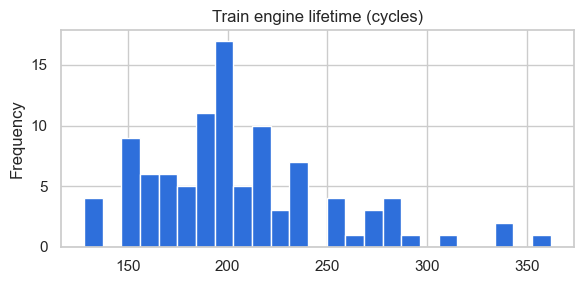

In [3]:
life = train.groupby("unit")["cycle"].max()
print(life.describe().round(1))
ax = life.plot.hist(bins=25, color="#2E6FDB", figsize=(6, 3), title="Train engine lifetime (cycles)"); plt.tight_layout()

## 2. Which sensors carry information?

flat sensors (dropped): ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
informative: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


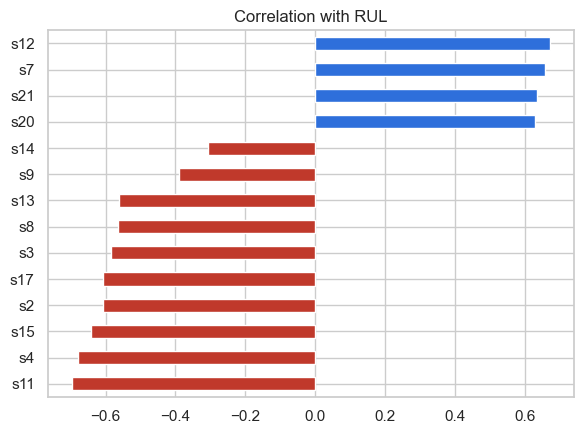

In [4]:
std = train[cmapss.SENSOR_COLS].std().sort_values()
keep = cmapss.informative_sensors(train)
print("flat sensors (dropped):", [s for s in cmapss.SENSOR_COLS if s not in keep])
print("informative:", keep)
corr = train[keep + ["rul"]].corr()["rul"].drop("rul").sort_values()
ax = corr.plot.barh(figsize=(6, 4.5), color=np.where(corr < 0, "#c0392b", "#2E6FDB"), title="Correlation with RUL")
plt.tight_layout()

## 3. Degradation trajectories (5 engines)

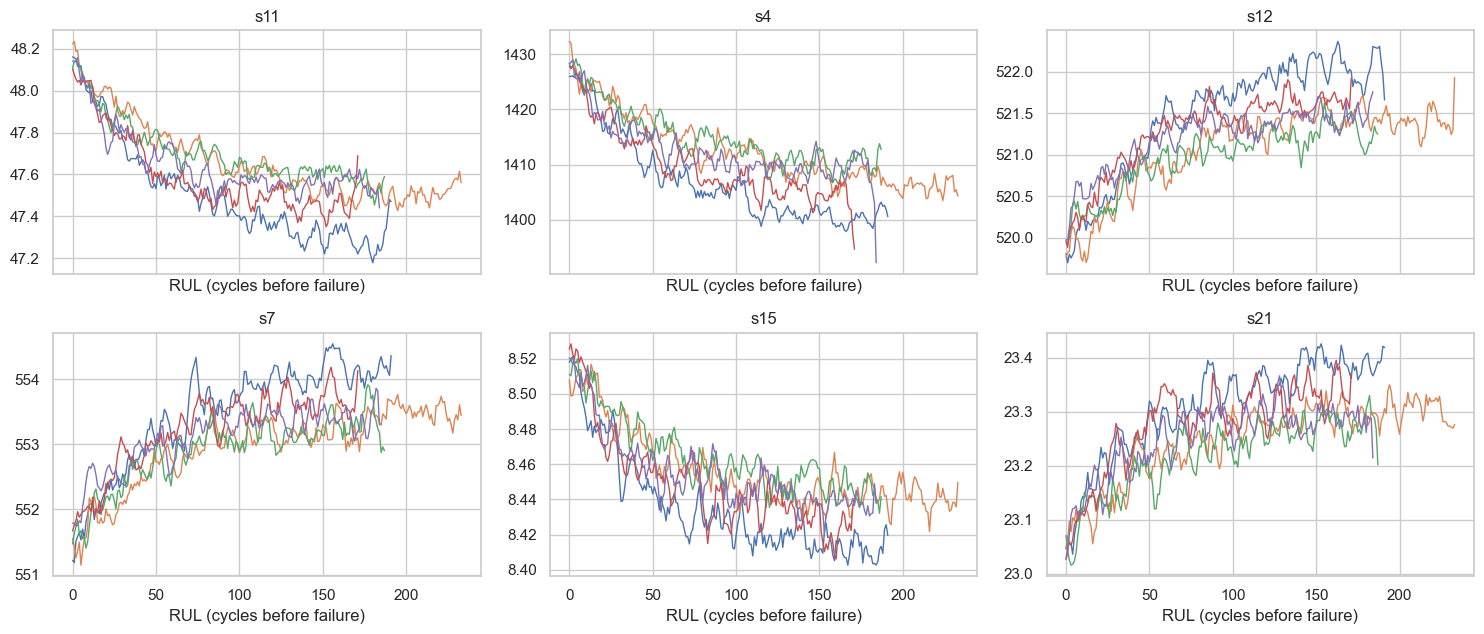

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for ax, s in zip(axes.ravel(), corr.abs().sort_values(ascending=False).index[:6]):
    for u in [1, 20, 40, 60, 80]:
        d = train[train.unit == u]
        ax.plot(d["rul"], d[s].rolling(5, min_periods=1).mean(), lw=1)
    ax.invert_xaxis(); ax.set_title(s); ax.set_xlabel("RUL (cycles before failure)")
plt.tight_layout()

Signals are flat early in life and degrade in the last ~100–150 cycles. That is why RUL targets are
usually **capped at 125** (piecewise-linear): the model is not asked to distinguish two healthy states.

## 4. The test set: what we have to predict

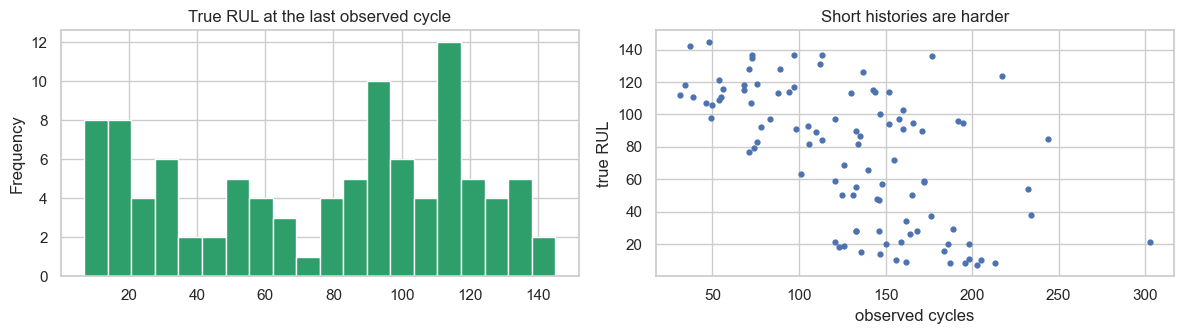

In [6]:
last = cmapss.last_cycles(test)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
last["rul"].plot.hist(bins=20, ax=axes[0], color="#2E9E6B", title="True RUL at the last observed cycle")
axes[1].scatter(last["cycle"], last["rul"], s=12); axes[1].set_xlabel("observed cycles"); axes[1].set_ylabel("true RUL")
axes[1].set_title("Short histories are harder"); plt.tight_layout()

## 5. Naive baseline to beat

In [7]:
pred = np.full(len(last), train.groupby("unit")["rul_capped"].mean().mean())
rmse_mean = np.sqrt(((pred - last["rul"].clip(upper=cmapss.RUL_CAP)) ** 2).mean())
print(f"Baseline 'predict the average RUL': RMSE = {rmse_mean:.1f} cycles on FD001 test (capped at {cmapss.RUL_CAP})")

Baseline 'predict the average RUL': RMSE = 41.5 cycles on FD001 test (capped at 125)


## Takeaways

- Keep the 14 informative sensors; drop 7 flat ones (`informative_sensors`).
- Cap RUL at 125; evaluate RMSE on the **last cycle** of each test engine (`last_cycles`).
- Any model in T20 must clearly beat the naive baseline above.
- Degradation shape (flat, then accelerating) is what the simulator's wear model should reproduce (T14).
- Cleaned data: `data/processed/cmapss_fd001_{train,test}.parquet`; DB `source = 'cmapss'`, 1 cycle = 1 h.